# Gaussian eddy experiment: exponential decay, H = 500 m

Analysis of `gaussian-eddy-exp-H500-d2c2280e`, segment `output000`. Horizontal coordinates and depth are in metres. These are transient model diagnostics, not an equilibrated circulation. Only this experiment is read; old-run output is not used as a fallback.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

## Open and verify the output

The selected experiment is `gaussian-eddy-exp-H500-d2c2280e`, with a 500 m exponential e-folding depth. `output000` is its fresh-start segment. Bathymetry and grid metrics come from that segment; forcing comes from the current configuration directory.

The next cell checks that all required diagnostics exist and verifies metre coordinates before plotting.

In [2]:
root = Path('/g/data/fu5/users/rd7475/github/phd/idealised_modelling/mom6_sandbox/mom6-idealised-eddy')
archive = Path('/scratch/fu5/rd7475/tmp/mom6-payu/archive/gaussian-eddy-exp-H500-d2c2280e')
output = archive / 'output000'
required = ['ocean_static.nc', 'ocean_daily.nc', 'ocean_month_z.nc', 'ocean.stats.nc']
missing = [name for name in required if not (output / name).is_file()]
if missing:
    raise FileNotFoundError(
        f'No complete H500 diagnostics available at {output}. Missing: {missing}. '
        f'Check job status and {archive / "error_logs"}; rerun after resolving initialization errors. '
        'This notebook does not substitute output from an older experiment.'
    )
time_decoder = xr.coders.CFDatetimeCoder(use_cftime=True)

static = xr.open_dataset(output / 'ocean_static.nc', decode_times=time_decoder)
daily = xr.open_dataset(output / 'ocean_daily.nc', decode_times=time_decoder)
vertical = xr.open_dataset(output / 'ocean_month_z.nc', decode_times=time_decoder)
stats = xr.open_dataset(output / 'ocean.stats.nc', decode_times=time_decoder)
forcing = xr.open_dataset(root / 'input' / 'forcing.nc')
datasets = [static, daily, vertical, stats, forcing]

for ds in [static, daily, vertical]:
    for name in ['xh', 'yh']:
        if ds[name].attrs.get('units') not in ('m', 'meter', 'meters', 'metre', 'metres'):
            raise ValueError(f'{output.name}: {name} is not in metres; select a metre-grid run.')
        ds[name].attrs.update(long_name='x position' if name == 'xh' else 'y position', units='m')
for name in ['x', 'y']:
    forcing[name].attrs.update(long_name=f'{name} position', units='m')
np.testing.assert_allclose(forcing.x.values, daily.xh.values)
np.testing.assert_allclose(forcing.y.values, daily.yh.values)
wet = static.wet.squeeze(drop=True) > 0
x_index = daily.sizes['xh'] // 2
x_section = float(daily.xh.isel(xh=x_index))
print('Output:', output)
print('Daily records:', daily.sizes['time'], '| first:', daily.time.values[0], '| last:', daily.time.values[-1])
print('Cell-centre x range (m):', float(daily.xh.min()), float(daily.xh.max()))
print('Cell-centre y range (m):', float(daily.yh.min()), float(daily.yh.max()))
for name in ['dxt', 'dyt']:
    print(f'{name} range (m):', float(static[name].min()), float(static[name].max()))
print('Section x (m):', x_section)
print('Last temperature averaging bounds:', vertical.time_bnds.isel(time=-1).values)


Output: /scratch/fu5/rd7475/tmp/mom6-payu/archive/gaussian-eddy-exp-H500-d2c2280e/output000
Daily records: 10 | first: 0001-01-01 12:00:00 | last: 0001-01-10 12:00:00
Cell-centre x range (m): 2500.0 497500.0
Cell-centre y range (m): 2500.0 497500.0
dxt range (m): 5000.0 5000.0
dyt range (m): 5000.0 5000.0
Section x (m): 252500.0
Last temperature averaging bounds: [ 9. 10.]


## Bathymetry and wind forcing

Bathymetry comes from this run. Both wind-stress components are shown along the selected x position. SST restoring is disabled in the current configuration, so no target-SST plot is included.

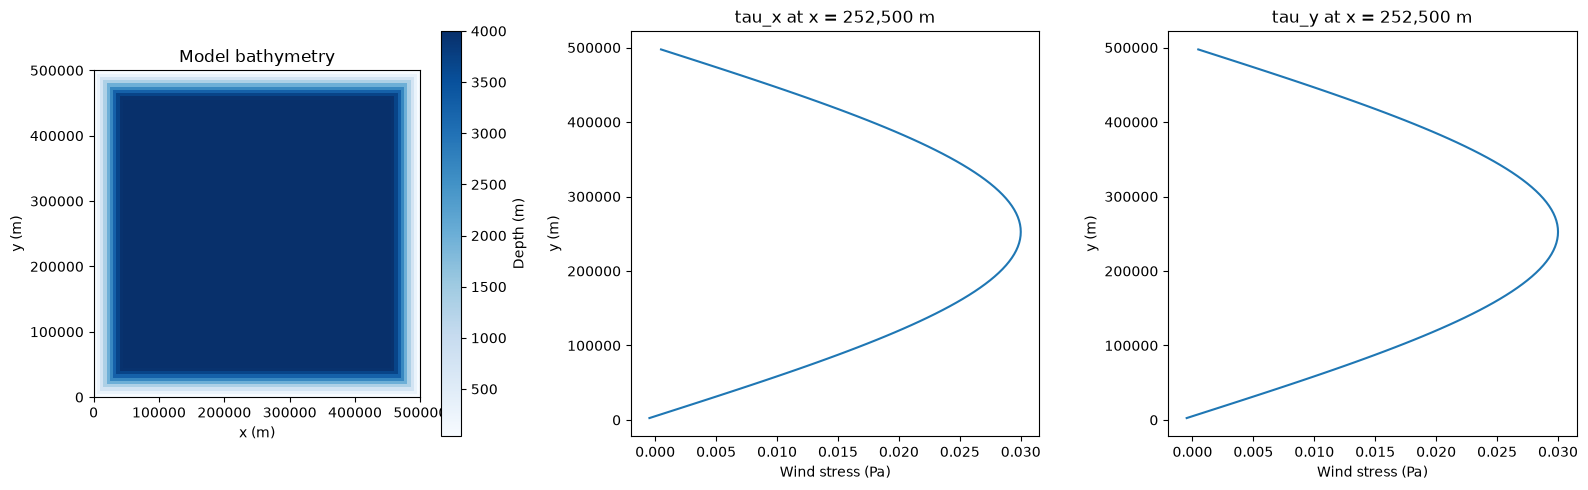

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
static.deptho.where(wet).plot(ax=axes[0], x='xh', y='yh', cmap='Blues', cbar_kwargs={'label': 'Depth (m)'})
axes[0].set_title('Model bathymetry')
axes[0].set_aspect('equal')
axes[0].set_xlabel('x (m)')
axes[0].set_ylabel('y (m)')
for ax, name in zip(axes[1:], ['tau_x', 'tau_y']):
    forcing[name].sel(x=x_section, method='nearest').plot(ax=ax, y='y')
    ax.set_title(f'{name} at x = {x_section:,.0f} m')
    ax.set_xlabel('Wind stress (Pa)')
    ax.set_ylabel('y (m)')
plt.tight_layout()

## Surface temperature and sea-surface height

The last available daily mean, masked over land. Horizontal y increases upwards.

Daily averaging bounds: [ 9. 10.]


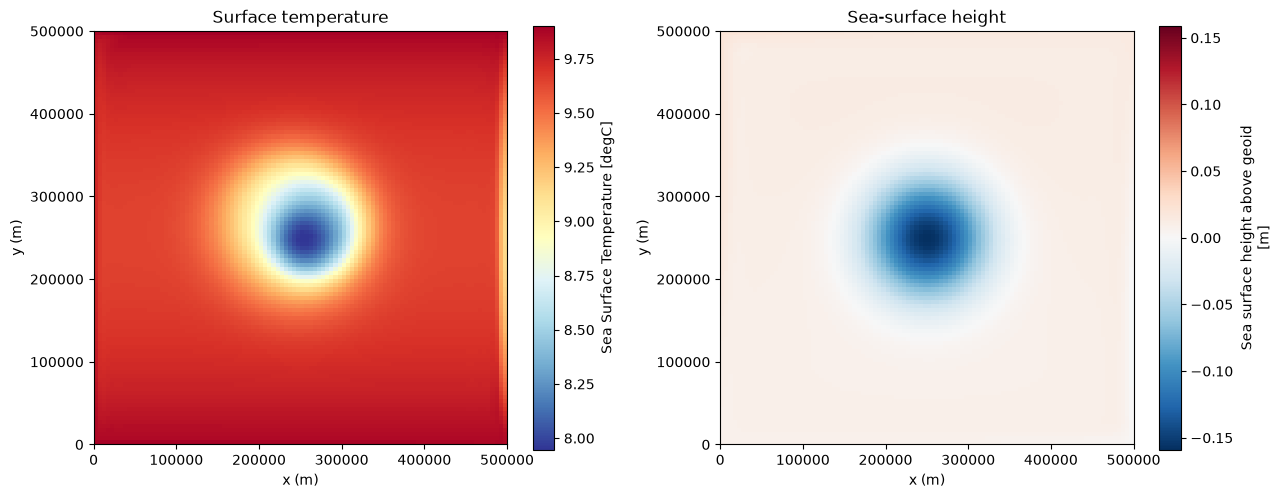

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name, title, cmap in zip(axes, ['tos', 'zos'], ['Surface temperature', 'Sea-surface height'], ['RdYlBu_r', 'RdBu_r']):
    daily[name].isel(time=-1).where(wet).plot(ax=ax, x='xh', y='yh', cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.set_aspect('equal')
print('Daily averaging bounds:', daily.time_bnds.isel(time=-1).values)
plt.tight_layout()

## Temperature sections and uppermost depth level

Use the last available depth-coordinate diagnostic. The filename `ocean_month_z.nc` does not guarantee monthly averaging: the actual time bounds are printed above. Depth increases downwards in the sections.

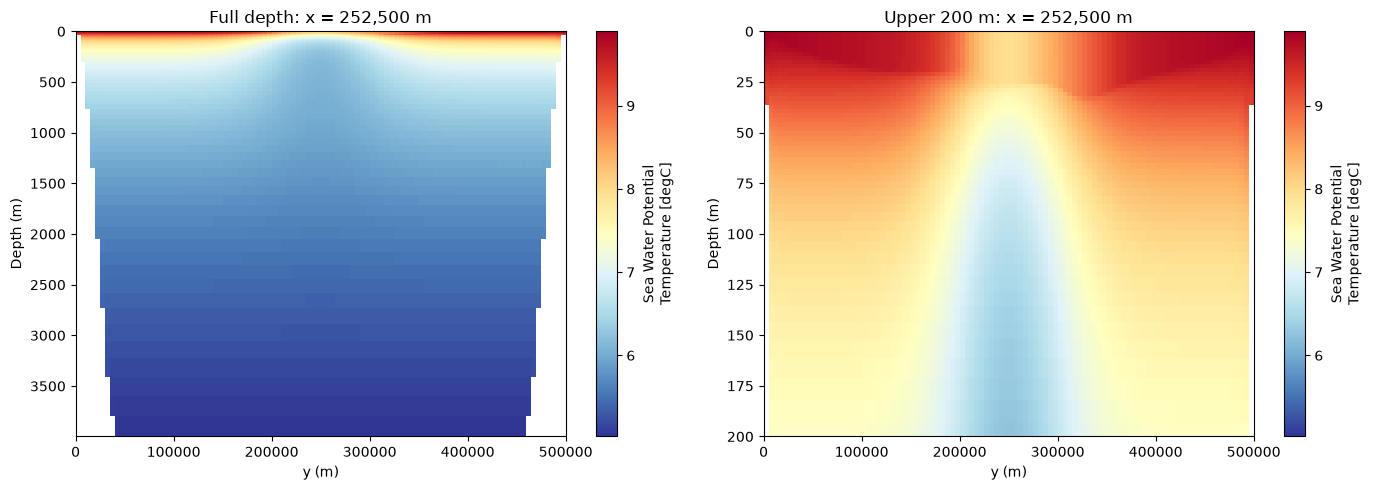

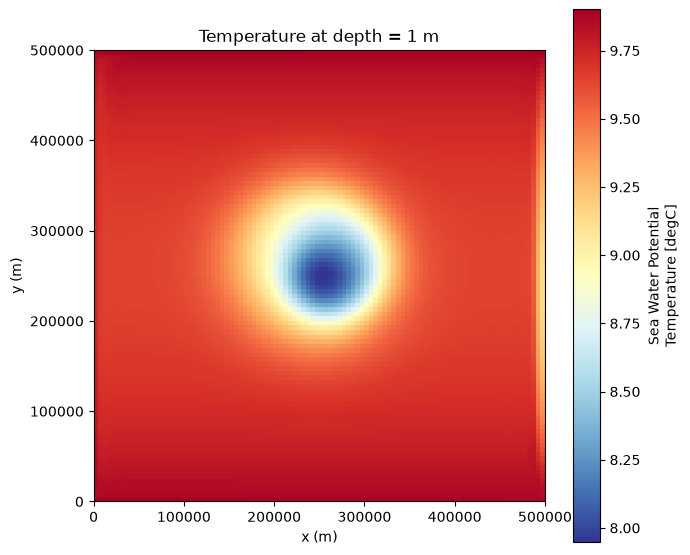

In [5]:
section = vertical.thetao.isel(time=-1, xh=x_index).where(wet.isel(xh=x_index))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, title in zip(axes, ['Full depth', 'Upper 200 m']):
    section.plot(ax=ax, x='yh', y='z_l', yincrease=False, cmap='RdYlBu_r')
    ax.set_xlabel('y (m)')
    ax.set_ylabel('Depth (m)')
    ax.set_title(f'{title}: x = {x_section:,.0f} m')
axes[1].set_ylim(200, 0)
plt.tight_layout()

fig, ax = plt.subplots(figsize=(7, 6))
surface = vertical.thetao.isel(time=-1, z_l=0).where(wet)
surface.plot(ax=ax, x='xh', y='yh', cmap='RdYlBu_r')
ax.set_title(f'Temperature at depth = {float(surface.z_l):g} m')
ax.set_xlabel('x (m)')
ax.set_ylabel('y (m)')
ax.set_aspect('equal')
plt.tight_layout()

## Basic model checks

Energy summed over layers and maximum transport CFL for this segment. These diagnostics describe transient evolution; they do not establish equilibrium.

tos min: 7.946865081787109 max: 9.90156078338623 degC
zos min: -0.15894566476345062 max: 0.02140858769416809 m
Maximum transport CFL in segment: 0.015232810807139186


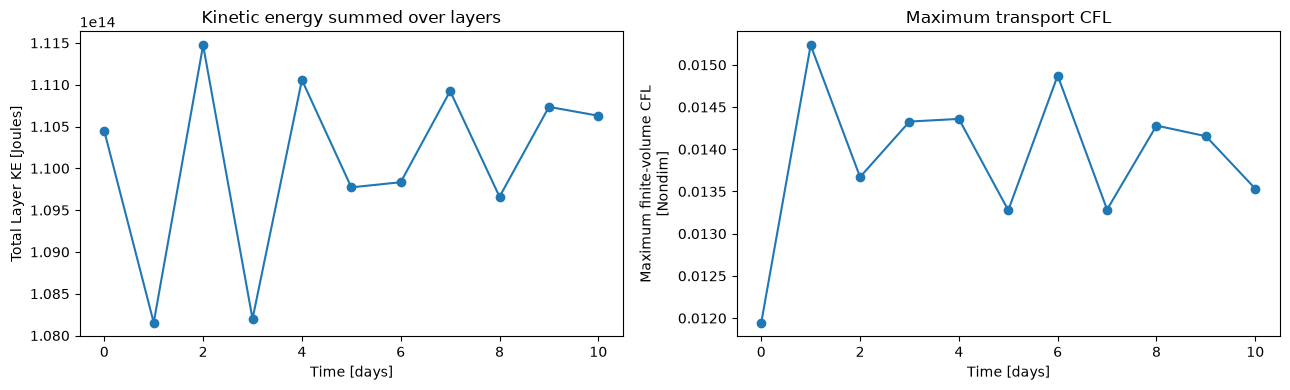

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
stats.KE.sum('Layer', keep_attrs=True).plot(ax=axes[0], marker='o')
axes[0].set_title('Kinetic energy summed over layers')
stats.max_CFL_trans.plot(ax=axes[1], marker='o')
axes[1].set_title('Maximum transport CFL')
plt.tight_layout()
for name in ['tos', 'zos']:
    field = daily[name].isel(time=-1).where(wet)
    print(name, 'min:', float(field.min()), 'max:', float(field.max()), field.attrs.get('units', ''))
print('Maximum transport CFL in segment:', float(stats.max_CFL_trans.max()))

In [7]:
for dataset in datasets:
    dataset.close()